# GDBN v6: Bayesian Confidence for Point-in-Time Return Rankings

Notebook 06 ranks stocks by the GDBN's **predicted** excess return, but ignores **how sure** it is. It also found that **trading costs** wipe out the small edge (the portfolio changes almost completely every day).

This notebook adds two things:

**Option 1: Bayesian weights.** For each stock and quarter:
1. The **lasso** picks the parents (arrows), as before.
2. A **Bayesian linear regression** on those parents gives each weight a **range** (posterior) instead of one number. Its prior and noise level are learned from the data (*empirical Bayes*, `sklearn`'s `BayesianRidge`).
3. Each prediction becomes a bell curve whose spread includes **both** everyday noise and **uncertainty about the weights**:

$$\text{predictive variance} = \underbrace{\sigma^2}_{\text{noise}} + \underbrace{x^\top \Sigma_w\, x}_{\text{weight uncertainty}}$$

4. From that: $P(\text{stock beats the group tomorrow}) = \Phi(\mu / s)$, with $\mu$ the predicted excess return, $s$ the predictive spread, and $\Phi$ the normal CDF.

**Option 2: Trade on confidence.** Instead of re-ranking from scratch every day:
- **Enter** a long when $P \ge c$ (or a short when $P \le 1 - c$), at most 20% of the universe per side.
- **Hold** until the signal flips ($P$ crosses 0.5), instead of selling as soon as the stock leaves the top 20%.

This should trade much less. The threshold $c$ is chosen on 2006–2020 by the **highest breakeven cost** (profit per unit traded: the rule most likely to survive costs), then checked on 2021–2022 (validation). Choosing by "Sharpe after costs" does not work when every option loses money after costs: it simply picks the rule that trades least. **Test years are not used.**

Same universe, walk-forward, and nodes as notebook 06 (see the vault note "Data Pipeline - Schemas and Joins").

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.linear_model import BayesianRidge, Lasso, lasso_path
from gdbn_utils import DATA, RESULTS, Z90

BUILT = DATA / "pit" / "built"
WINDOW, TOP_FRAC, COST_BPS = 756, 0.20, 5
SENT_KIND = "news"
ALPHAS = np.logspace(-0.7, -3, 20)
TUNE_END, EVAL_END = "2020-12-31", "2022-12-31"   # test years locked
ETFS = ["SPY", "USO", "GLD", "DBC", "TLT"]
C_GRID = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75]           # entry thresholds for P(beat the group)

days = pd.DatetimeIndex(pd.read_csv(BUILT / "trading_days.csv", parse_dates=["date"])["date"])
panel = pd.read_csv(BUILT / "panel.csv.gz", parse_dates=["date"],
                    usecols=["date", "permno", "ret", f"n_{SENT_KIND}", f"sent_{SENT_KIND}"])
RET = panel.pivot(index="date", columns="permno", values="ret").reindex(days)
SENT = panel.pivot(index="date", columns="permno", values=f"sent_{SENT_KIND}").reindex(days)
ATTN = np.log1p(panel.pivot(index="date", columns="permno", values=f"n_{SENT_KIND}")).reindex(days)
ETF = pd.read_csv(BUILT / "etf_returns.csv", index_col="date", parse_dates=True).reindex(days)[ETFS]
del panel
sel = pd.read_csv(BUILT / "universe.csv", parse_dates=["rebalance_date"]).query("selected")
rebal = [pd.Timestamp(r) for r in sorted(sel["rebalance_date"].unique()) if r <= pd.Timestamp(EVAL_END)]
U_PIT = {r: list(g["permno"]) for r, g in sel.groupby("rebalance_date") if r in rebal}
print(f"{len(rebal)} quarters, point-in-time universe")

68 quarters, point-in-time universe


## 1. Walk-forward data for one quarter

Same as notebook 06: inputs at $t-1$ (each stock's excess return, sentiment, attention, plus 5 ETFs), z-scored with the past-3-year window's statistics.

In [ ]:
def quarter_data(r, nxt, U):
    pos = days.searchsorted(r)
    if pos - WINDOW - 1 < 0:
        return None
    hold = days[pos: days.searchsorted(nxt)]
    hold = hold[hold <= pd.Timestamp(EVAL_END)]
    if len(hold) == 0:
        return None
    win = days[pos - WINDOW: pos]
    span = days[pos - WINDOW - 1: pos + len(hold)]
    R = RET.reindex(index=span, columns=U)
    EX = R.sub(R.mean(axis=1), axis=0)
    X = pd.concat([EX.add_suffix("|ret"), SENT.reindex(index=span, columns=U).add_suffix("|sent"),
                   ATTN.reindex(index=span, columns=U).add_suffix("|attn"), ETF.reindex(span)], axis=1).shift(1)
    Xw, Xh = X.loc[win], X.loc[hold]
    mu, sd = Xw.mean(), Xw.std().replace(0, np.nan)
    Xwz, Xhz = ((Xw - mu) / sd).fillna(0).values, ((Xh - mu) / sd).fillna(0).values
    xm = Xwz.mean(axis=0)
    return {"r": r, "hold": hold, "U": U, "Xc": Xwz - xm, "Xhc": Xhz - xm, "Y": EX.loc[win].values}


def quarters():
    for j, r in enumerate(rebal):
        nxt = rebal[j + 1] if j + 1 < len(rebal) else pd.Timestamp(EVAL_END) + pd.Timedelta(days=1)
        q = quarter_data(r, pd.Timestamp(nxt), U_PIT[r])
        if q is not None:
            yield q
print("ready")

ready


## 2. Choose the shared λ (same rule as notebook 06)

The λ with the best average rank IC over the 2006–2020 walk-forward.

In [ ]:
def daily_ic(score, start, end):
    s = score.loc[start:end]
    r = RET.reindex(index=s.index, columns=s.columns)
    ok = s.notna() & r.notna()
    e = r.where(ok).sub(r.where(ok).mean(axis=1), axis=0)
    return s.where(ok).rank(axis=1).corrwith(e.rank(axis=1), axis=1).fillna(0.0)

path_parts = {k: [] for k in range(len(ALPHAS))}
for q in quarters():
    S = np.full((len(ALPHAS), len(q["hold"]), len(q["U"])), np.nan)
    for i in range(len(q["U"])):
        y = q["Y"][:, i]; ok = ~np.isnan(y)
        if ok.sum() < 252:
            continue
        ys = y[ok].std()
        _, coefs, _ = lasso_path(q["Xc"][ok], (y[ok] - y[ok].mean()) / ys, alphas=ALPHAS)
        S[:, :, i] = (q["Xhc"] @ coefs).T * ys
    for k in range(len(ALPHAS)):
        path_parts[k].append(pd.DataFrame(S[k], index=q["hold"], columns=q["U"]))
ic = [daily_ic(pd.concat(path_parts[k]).sort_index(), None, TUNE_END).mean() for k in range(len(ALPHAS))]
K = int(np.argmax(ic))
ALPHA = ALPHAS[K]
del path_parts
print(f"Shared λ = {ALPHA:.4f} (2006–2020 rank IC {ic[K]:.4f})")

Shared λ = 0.0865 (2006–2020 rank IC 0.0088)


## 3. Bayesian regression on the lasso's chosen parents (Option 1)

For each stock and quarter: lasso at the chosen λ → parents → `BayesianRidge` on those parents. Saved for every holding day:
- **lasso score:** the lasso's prediction (as in notebook 06)
- **μ:** the Bayesian posterior-mean prediction (dynamic part only, like notebook 06)
- **s:** predictive spread (noise + weight uncertainty); **σ:** noise only
- **P = Φ(μ / s):** probability the stock beats the group tomorrow

In [ ]:
cols = ["lasso", "mu", "mu_full", "s", "sigma"]
parts = {c: [] for c in cols}
param_share, n_parents = [], []
for q in quarters():
    n_h, n_u = len(q["hold"]), len(q["U"])
    out = {c: np.full((n_h, n_u), np.nan) for c in cols}
    for i in range(n_u):
        y = q["Y"][:, i]; ok = ~np.isnan(y)
        if ok.sum() < 252:
            continue
        ym, ys = y[ok].mean(), y[ok].std()
        yz = (y[ok] - ym) / ys
        w = Lasso(alpha=ALPHA, max_iter=10000).fit(q["Xc"][ok], yz).coef_
        par = np.nonzero(w)[0]
        n_parents.append(len(par))
        out["lasso"][:, i] = (q["Xhc"] @ w) * ys
        if len(par) == 0:                                       # no parents: predict the average, spread = noise
            out["mu"][:, i], out["mu_full"][:, i] = 0.0, ym
            out["s"][:, i] = out["sigma"][:, i] = ys * np.sqrt(1 + 1 / ok.sum())
            continue
        br = BayesianRidge(fit_intercept=True).fit(q["Xc"][ok][:, par], yz)
        m, s = br.predict(q["Xhc"][:, par], return_std=True)
        sigma = 1 / np.sqrt(br.alpha_)                          # noise only
        out["mu"][:, i] = (m - br.intercept_) * ys               # dynamic part (no stock-specific average)
        out["mu_full"][:, i] = m * ys + ym
        out["s"][:, i], out["sigma"][:, i] = s * ys, sigma * ys
        param_share.append(np.mean(1 - sigma ** 2 / s ** 2))     # share of the variance from weight uncertainty
    for c in cols:
        parts[c].append(pd.DataFrame(out[c], index=q["hold"], columns=q["U"]))
F = {c: pd.concat(v).sort_index() for c, v in parts.items()}
F["P"] = pd.DataFrame(norm.cdf(F["mu"] / F["s"]), index=F["mu"].index, columns=F["mu"].columns).where(F["mu"].notna())
print(f"Parents per stock: median {np.median(n_parents):.0f}; with none: {np.mean(np.array(n_parents) == 0):.0%}")
print(f"Share of predictive variance from WEIGHT uncertainty: {100 * np.mean(param_share):.2f}% on average "
      f"(the rest is day-to-day noise)")
print("P(beat the group): percentiles", np.nanpercentile(F["P"].values, [1, 10, 50, 90, 99]).round(4))

Parents per stock: median 4; with none: 3%
Share of predictive variance from WEIGHT uncertainty: 0.56% on average (the rest is day-to-day noise)
P(beat the group): percentiles [0.2887 0.417  0.5    0.5842 0.7128]


**Reading it:**
- **Weight uncertainty** is usually a tiny share of the spread: daily returns are mostly noise, so $s \approx \sigma$.
- **The range of $P$:** if $P$ often reaches 0.3 or 0.7, the model *claims* a lot of confidence. Whether that confidence is real is checked next (calibration).

## 4. Are the probabilities calibrated?

If the model says $P = 0.52$, the stock should beat the group about 52% of the time. Bins of $P$ vs the share of stocks that actually beat the group (2006–2020 and 2021–2022). Also: does $\mu \pm 1.645\,s$ contain the actual excess return 90% of the time?

In [ ]:
E = RET.reindex(index=F["P"].index, columns=F["P"].columns)
E = E.where(F["P"].notna())
E = E.sub(E.mean(axis=1), axis=0)                                # actual excess return vs the universe

for name, (a, b) in {"2006–2020": (None, TUNE_END), "2021–2022": ("2021-01-01", EVAL_END)}.items():
    p, e = F["P"].loc[a:b].stack(), E.loc[a:b].stack()
    d = pd.DataFrame({"P": p, "beat": e > 0}).dropna()
    d["bin"] = pd.qcut(d["P"], 10, duplicates="drop")
    cal = d.groupby("bin", observed=True).agg(mean_P=("P", "mean"), actual_share=("beat", "mean"), n=("P", "size"))
    cov_s = ((E - F["mu_full"]).abs() <= Z90 * F["s"]).where(E.notna()).loc[a:b].stack().mean()
    cov_n = ((E - F["mu_full"]).abs() <= Z90 * F["sigma"]).where(E.notna()).loc[a:b].stack().mean()
    print(f"===== {name}: 90% range coverage: with weight uncertainty {cov_s:.3f}, noise only {cov_n:.3f}")
    print(cal.round(4).to_string(), "\n")

===== 2006–2020: 90% range coverage: with weight uncertainty 0.896, noise only 0.895
                    mean_P actual_share      n
bin                                           
(-0.000546, 0.419]  0.3636     0.488957  19016
(0.419, 0.453]      0.4377     0.487405  19015
(0.453, 0.473]      0.4633     0.489167  19016
(0.473, 0.489]      0.4810     0.494846  19014
(0.489, 0.5]        0.4960     0.490299  21801
(0.5, 0.512]        0.5057     0.497997  16229
(0.512, 0.527]      0.5192     0.498606  19015
(0.527, 0.548]      0.5371     0.503602  19015
(0.548, 0.582]      0.5632     0.493821  19015
(0.582, 0.999]      0.6381     0.501315  19016 

===== 2021–2022: 90% range coverage: with weight uncertainty 0.914, noise only 0.913
                 mean_P  actual_share     n
bin                                        
(0.0686, 0.403]  0.3544        0.4890  2767
(0.403, 0.441]   0.4240        0.4939  2766
(0.441, 0.464]   0.4527        0.4684  2767
(0.464, 0.483]   0.4737        0.4971  2766


**Reading it:**
- **Calibrated** = `actual_share` close to `mean_P` in every row.
- **Overconfident** = `mean_P` spreads from about 0.35 to 0.65 but `actual_share` stays near 0.5: the model's confidence is mostly not real. This happens when the predicted mean moves a lot (e.g., on volatile days, inputs far from their usual range push predictions to extremes) while the true signal is tiny.
- **Coverage** near 90% means the *spread* is right on average; calibration of $P$ is about the *direction*, which is the hard part.
- `actual_share` is a bit below 0.5 overall because excess returns are skewed (a few big winners, many small losers).

## 5. Trading rules (Option 2)

All rules are **market-neutral** (profits measured on excess returns vs the universe), with costs of 5 bps per unit traded.

| Rule | Each day |
|---|---|
| **Lasso rank** (notebook 06) | buy the top 20% by lasso score, short the bottom 20% |
| **Bayesian rank** | the same, ranked by $P$ (i.e., by $\mu / s$: prefers confident predictions) |
| **Confidence hold** ($c$) | **enter** long if $P \ge c$, short if $P \le 1 - c$ (most confident first, at most 20% per side); **hold** until $P$ crosses 0.5 |

In [ ]:
def nw_t(x, lags=5):
    x = np.asarray(x, dtype=float); x = x[~np.isnan(x)]; n = len(x); xc = x - x.mean()
    var = xc @ xc / n
    for k in range(1, lags + 1):
        var += 2 * (1 - k / (lags + 1)) * (xc[k:] @ xc[:-k]) / n
    return x.mean() / np.sqrt(var / n) if var > 0 else np.nan


def rank_weights(score):
    ok = score.notna() & E.notna()
    s = score.where(ok)
    rk = (s.rank(axis=1) + np.random.default_rng(1).uniform(0, 1e-9, s.shape)).where(ok).rank(axis=1)
    n = ok.sum(axis=1)
    top = np.maximum(np.floor(n * TOP_FRAC), 1)
    return (rk.gt(n - top, axis=0).astype(float).div(top, axis=0) - rk.le(top, axis=0).astype(float).div(top, axis=0)).where(ok, 0.0)


def hold_weights(P, c):
    longs, shorts, rows = set(), set(), []
    Pv, Ev = P.values, E.notna().values
    for t in range(len(P)):
        p = pd.Series(Pv[t], index=P.columns)[Ev[t]].dropna()
        cap = max(int(np.floor(len(p) * TOP_FRAC)), 1)
        longs = {s for s in longs if s in p.index and p[s] >= 0.5}       # hold until the signal flips
        shorts = {s for s in shorts if s in p.index and p[s] <= 0.5}
        for s in p[p >= c].sort_values(ascending=False).index:           # enter, most confident first
            if len(longs) >= cap:
                break
            if s not in shorts:
                longs.add(s)
        for s in p[p <= 1 - c].sort_values().index:
            if len(shorts) >= cap:
                break
            if s not in longs:
                shorts.add(s)
        w = pd.Series(0.0, index=P.columns)
        if longs:
            w[list(longs)] = 1 / len(longs)
        if shorts:
            w[list(shorts)] = -1 / len(shorts)
        rows.append(w.values)
    return pd.DataFrame(rows, index=P.index, columns=P.columns)


def summary(w, a, b):
    w = w.loc[a:b]
    pnl = (w * E.loc[a:b].fillna(0)).sum(axis=1)
    turn = w.diff().abs().sum(axis=1); turn.iloc[0] = w.iloc[0].abs().sum()
    net = pnl - turn * COST_BPS / 1e4
    return pd.Series({"bps/day": pnl.mean() * 1e4, "t": nw_t(pnl), "Sharpe gross": pnl.mean() / pnl.std() * np.sqrt(252),
                      "Sharpe net": net.mean() / net.std() * np.sqrt(252), "turnover/day": turn.mean(),
                      "breakeven bps": pnl.mean() / turn.mean() * 1e4 if turn.mean() > 0 else np.nan,
                      "days invested": (w.abs().sum(axis=1) > 0).mean()})


W_rules = {"Lasso rank (notebook 06)": rank_weights(F["lasso"]), "Bayesian rank (by P)": rank_weights(F["P"])}
grid = {}
for c in C_GRID:
    W_rules[f"Confidence hold, c = {c}"] = hold_weights(F["P"], c)
    grid[c] = summary(W_rules[f"Confidence hold, c = {c}"], None, TUNE_END)
grid = pd.DataFrame(grid).T
grid.index.name = "entry threshold c"
print("Choosing c on 2006–2020 (highest breakeven cost = profit per unit traded):")
print(grid.round(3).to_string())
C_BEST = float(grid["breakeven bps"].idxmax())
print(f"\nChosen c = {C_BEST}")

Choosing c on 2006–2020 (highest breakeven cost = profit per unit traded):
                   bps/day      t  Sharpe gross  Sharpe net  turnover/day  breakeven bps  days invested
entry threshold c                                                                                      
0.50                 3.915  3.012         0.745      -0.917         1.747          2.241          1.000
0.55                 4.241  3.149         0.792      -0.918         1.832          2.315          1.000
0.60                 4.178  2.282         0.594      -0.846         2.026          2.062          0.999
0.65                 1.243  0.549         0.143      -0.718         1.502          0.828          0.886
0.70                 0.106  0.048         0.012      -0.457         0.807          0.132          0.555
0.75                 0.040  0.023         0.005      -0.259         0.419          0.097          0.283

Chosen c = 0.55


## 6. Results: 2006–2020 walk-forward and 2021–2022 validation

===== 2006–2020 walk-forward =====
                           bps/day      t  Sharpe gross  Sharpe net  turnover/day  breakeven bps  days invested
Lasso rank (notebook 06)     2.597  1.890         0.464      -1.975         2.727          0.952            1.0
Bayesian rank (by P)         3.778  2.763         0.713      -2.041         2.917          1.295            1.0
Confidence hold, c = 0.55    4.241  3.149         0.792      -0.918         1.832          2.315            1.0
S&P 500 (SPY, buy & hold)    4.463    NaN         0.556       0.556           NaN            NaN            NaN 

===== 2021–2022 validation =====
                           bps/day      t  Sharpe gross  Sharpe net  turnover/day  breakeven bps  days invested
Lasso rank (notebook 06)     5.150  1.234         0.903      -1.633         2.894          1.780            1.0
Bayesian rank (by P)         4.916  1.072         0.904      -1.869         3.018          1.629            1.0
Confidence hold, c = 0.55    3.952

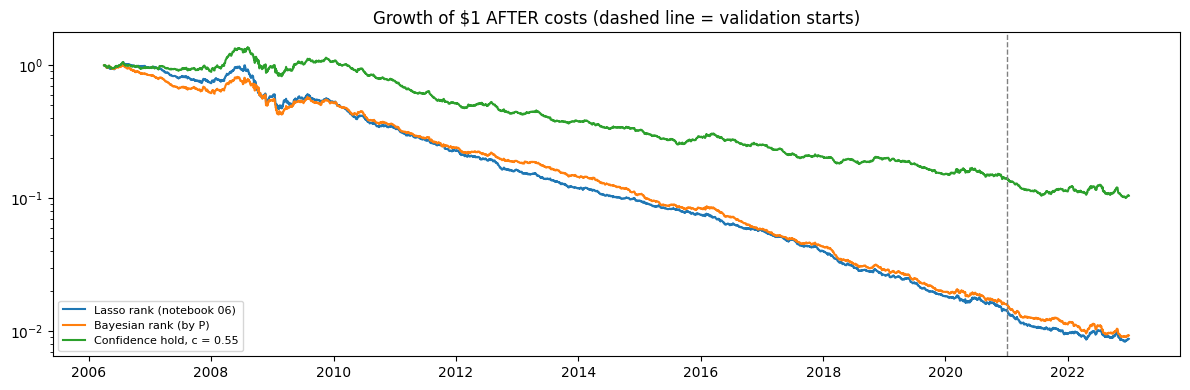

In [ ]:
show = ["Lasso rank (notebook 06)", "Bayesian rank (by P)", f"Confidence hold, c = {C_BEST}"]
results = {}
for name, (a, b) in {"2006–2020 walk-forward": (None, TUNE_END), "2021–2022 validation": ("2021-01-01", EVAL_END)}.items():
    tab = pd.DataFrame({k: summary(W_rules[k], a, b) for k in show}).T
    spy = ETF.loc[F["P"].loc[a:b].index, "SPY"]
    tab.loc["S&P 500 (SPY, buy & hold)", ["bps/day", "Sharpe gross", "Sharpe net"]] = [
        spy.mean() * 1e4, spy.mean() / spy.std() * np.sqrt(252), spy.mean() / spy.std() * np.sqrt(252)]
    results[name] = tab
    print(f"===== {name} =====")
    print(tab.round(3).to_string(), "\n")

fig, ax = plt.subplots(figsize=(12, 4))
for k in show:
    w = W_rules[k]
    pnl = (w * E.fillna(0)).sum(axis=1) - w.diff().abs().sum(axis=1).fillna(0) * COST_BPS / 1e4
    ax.plot((1 + pnl).cumprod(), label=k)
ax.axvline(pd.Timestamp("2021-01-01"), color="gray", ls="--", lw=1)
ax.set_yscale("log"); ax.set_title("Growth of $1 AFTER costs (dashed line = validation starts)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the results:**
- **Turnover** is the key column: the lasso rank changes almost the whole portfolio daily (turnover near 3 of a possible 4); the confidence hold should trade far less.
- **Breakeven bps:** the trading cost at which profits are zero. If it rises above about 5 bps, the strategy survives realistic costs.
- **Days invested:** with a high threshold, some days have no confident stocks, so the portfolio sits in cash.
- If the probabilities are overconfident (section 4), the threshold works as a **score cutoff** rather than a true probability; the gain (if any) comes mostly from **holding positions longer**, which cuts turnover.
- $c$ was chosen on 2006–2020, so **2021–2022 is the honest check**.

## 7. Does the signal last? (IC decay)

Holding a stock for several days only pays if today's ranking still predicts returns **after** tomorrow. Three views, for the lasso score and for $P$:

1. **Day-$k$ IC:** rank correlation between today's score and the excess return **$k$ days later** ($k = 1$ is the usual next-day IC). How fast does the information fade?
2. **Cumulative IC:** rank correlation between today's score and the **total** excess return over the next $h$ days. This is what a portfolio held for $h$ days earns.
3. **Ranking stability:** rank correlation between today's score and the score $k$ days later. High = the ranking changes slowly, so holding is natural (and cheap).

Future returns stop at the end of 2022: **nothing from the test years is used.**

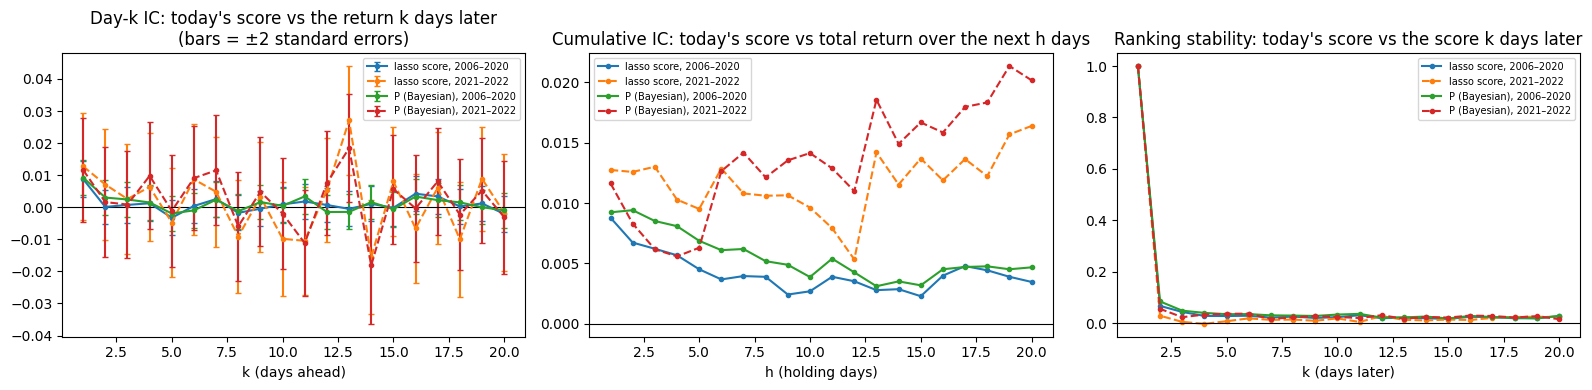

===== lasso, 2006–2020 =====
    day-k IC  day-k SE  cumulative IC  ranking stability
1     0.0088    0.0028         0.0088             1.0000
2     0.0001    0.0027         0.0067             0.0667
3     0.0007    0.0028         0.0062             0.0433
5    -0.0033    0.0027         0.0045             0.0273
10    0.0009    0.0027         0.0027             0.0230
20   -0.0021    0.0028         0.0035             0.0264 

===== lasso, 2021–2022 =====
    day-k IC  day-k SE  cumulative IC  ranking stability
1     0.0127    0.0083         0.0127             1.0000
2     0.0071    0.0087         0.0126             0.0285
3     0.0026    0.0085         0.0130             0.0045
5    -0.0048    0.0085         0.0095             0.0070
10   -0.0098    0.0089         0.0096             0.0181
20   -0.0017    0.0091         0.0164             0.0233 

===== P, 2006–2020 =====
    day-k IC  day-k SE  cumulative IC  ranking stability
1     0.0092    0.0027         0.0092             1.0000
2

In [ ]:
RETv = RET.loc[:EVAL_END]                       # future returns end at EVAL_END (test years never touched)
LAGS = list(range(1, 21))

def excess_ahead(score, k):
    # Excess return k days after the score's day (k = 1: the day the score is for), same stocks as that day's universe
    fut = RETv.shift(-(k - 1)).reindex(index=score.index, columns=score.columns)
    fut = fut.where(score.notna())
    return fut.sub(fut.mean(axis=1), axis=0)

def rank_ic(score, target):
    ok = score.notna() & target.notna()
    ic = score.where(ok).rank(axis=1).corrwith(target.where(ok).rank(axis=1), axis=1)
    return ic[ok.sum(axis=1) >= 10]

decay = {}
for sig in ["lasso", "P"]:
    for period, (a, b) in {"2006–2020": (None, TUNE_END), "2021–2022": ("2021-01-01", EVAL_END)}.items():
        S = F[sig].loc[a:b]
        day_k, cum_h, stab = [], [], []
        cum = None
        for k in LAGS:
            e = excess_ahead(S, k)
            ick = rank_ic(S, e)
            day_k.append((ick.mean(), ick.std() / np.sqrt(len(ick))))
            cum = e if cum is None else cum + e.fillna(0).where(cum.notna())
            ich = rank_ic(S, cum)
            cum_h.append(ich.mean())
            later = F[sig].shift(-(k - 1)).reindex(index=S.index) if k > 1 else S
            stab.append(rank_ic(S, later.where(S.notna())).mean() if k > 1 else 1.0)
        decay[(sig, period)] = pd.DataFrame({"day-k IC": [d[0] for d in day_k], "day-k SE": [d[1] for d in day_k],
                                             "cumulative IC": cum_h, "ranking stability": stab}, index=LAGS)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for (sig, period), d in decay.items():
    ls = "-" if period == "2006–2020" else "--"
    lab = f"{'lasso score' if sig == 'lasso' else 'P (Bayesian)'}, {period}"
    axes[0].errorbar(d.index, d["day-k IC"], yerr=2 * d["day-k SE"], ls=ls, marker="o", ms=3, capsize=2, label=lab)
    axes[1].plot(d.index, d["cumulative IC"], ls=ls, marker="o", ms=3, label=lab)
    axes[2].plot(d.index, d["ranking stability"], ls=ls, marker="o", ms=3, label=lab)
axes[0].set_title("Day-k IC: today's score vs the return k days later\n(bars = ±2 standard errors)")
axes[1].set_title("Cumulative IC: today's score vs total return over the next h days")
axes[2].set_title("Ranking stability: today's score vs the score k days later")
for ax, xl in zip(axes, ["k (days ahead)", "h (holding days)", "k (days later)"]):
    ax.axhline(0, color="black", lw=0.8); ax.set_xlabel(xl); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for (sig, period), d in decay.items():
    print(f"===== {sig}, {period} =====")
    print(d.loc[[1, 2, 3, 5, 10, 20]].round(4).to_string(), "\n")

**Reading it:**
- **Day-$k$ IC:** if only $k = 1$ is clearly above 0 (outside its ±2 SE bars), the information is used up in one day and holding longer mostly adds noise. If $k = 2$–$5$ stay positive, the signal lasts and holding pays.
- **Cumulative IC:** if it keeps rising with $h$, the signal lasts. If it is flat or falls after $h = 1$, it does not.
- **Ranking stability:** low (near 0 after a few days) means the ranking reshuffles fast, which is why the daily portfolio trades so much. A **smoothed** score (average of the last few days) would be more stable; it only helps if the day-$k$ IC stays positive.

## 8. Save results

In [ ]:
RESULTS.mkdir(parents=True, exist_ok=True)
grid.to_csv(RESULTS / "pit_bayes_threshold_grid.csv")
pd.concat(results, names=["period", "rule"]).to_csv(RESULTS / "pit_bayes_results.csv")
pd.Series({"alpha": ALPHA, "c_best": C_BEST}).to_csv(RESULTS / "pit_bayes_settings.csv")
pd.concat(decay, names=["signal", "period", "k"]).to_csv(RESULTS / "pit_ic_decay.csv")
print("Saved to", RESULTS)

Saved to /Users/max_lovinger/Documents/Thesis/CoreFragment/data/results
